# <p style='color:orange'> dreampy figures </p>
    
  Notebook to generate figures for dreampy manuscript.

In [1]:
# Standard library imports
import os
import sys
import glob

# Third-party libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
from scipy.stats import pearsonr
from matplotlib_venn import venn2
from scipy.cluster.hierarchy import linkage, leaves_list

# Suppress specific warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)

# Show matplotlib plots
plt.show()

#Set font
plt.rcParams['font.family'] = 'Arial'
sns.set_theme(font='Arial')

# Import custom items
sys.path.append(os.path.abspath("../"))
import plotting as pl
from utils.constants import DICTIONARIES, RANDOM_STATE, MM

# Set general rcParams for matplotlib
plt.rcParams.update(DICTIONARIES['general_rcParams'])

## <b style='color:magenta'> paths

In [2]:
FIGURES_PATH = Path("../figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

DATA_PATH = Path("../validation/data")

## <b style='color:magenta'> Figure 2


### metric plots

In [3]:
# ── Helpers ──────────────────────────────────────────────────────────

def load_merge_cols(assay, comparison, left_col, right_col):
    """Merge R and Python CSVs on index, return DataFrame with _r/_py suffixes."""
    r = pd.read_csv(f"{DATA_PATH}/wells2025/{assay}_ref_{comparison}.csv", index_col=0)
    py = pd.read_csv(f"{DATA_PATH}/wells2025/{assay}_py_{comparison}.csv", index_col=0)
    merged = r.merge(py, left_index=True, right_index=True, suffixes=("_r", "_py"))
    return merged, f"{left_col}_r", f"{right_col}_py"


def load_merge_ravel(assay, comparison, n_sample=None, seed=11):
    """Ravel R and Python matrices into paired columns."""
    r = pd.read_csv(f"{DATA_PATH}/wells2025/{assay}_ref_{comparison}.csv", index_col=0)
    py = pd.read_csv(f"{DATA_PATH}/wells2025/{assay}_py_{comparison}.csv", index_col=0)
    return pd.DataFrame({"r": r.values.ravel(), "py": py.values.ravel()})   


def annotate_pearson(x, y):
    r, _ = pearsonr(x, y)
    return f"Pearson's r = {r:.7f}"


def annotate_max_delta(x, y):
    return f"max |Δ| = {np.max(np.abs(y - x)):3e}"

In [4]:
assay_name = "cd4_treg"

PLOTS = [
    dict(comparison="tmm_factors", merge="cols",
         col="norm_factors", title="TMM factors",
         lim=(0.8, 1.4), ticks=[0.8, 1.0, 1.2, 1.4],
         annotate_fn=annotate_pearson, annotate_pos=(0.92, 0.82)),

    dict(comparison="log2cpm", merge="ravel", n_sample=10_000,
         title="Log2CPM",
         lim=(-5, 15.5), ticks=[-5, 0, 5, 10, 15],
         annotate_fn=annotate_max_delta, annotate_pos=(-1.8, -4.5)),

    dict(comparison="voom_weights", merge="ravel", n_sample=10_000,
         title="Voom weights",
         lim=(0, 45), ticks=[0, 20, 40],
         annotate_fn=annotate_pearson, annotate_pos=(7, 0.82)),

    dict(comparison="lmer", merge="cols",
         col="stdev_unscaled_age_groups1", title="Unscaled SE",
         lim=(0, 2.5), ticks=[0, 1, 2],
         annotate_fn=annotate_pearson, annotate_pos=(0.37, 0.05),
         save_name="stdev_unscaled"),

    dict(comparison="ebayes", merge="cols",
         col="t_age_groups1", title="t-statistic",
         lim=(-5, 5), ticks=[-4, -2, 0, 2, 4],
         annotate_fn=annotate_pearson, annotate_pos=(-2, -4.5),
         save_name="t_stat"),

    dict(comparison="ebayes", merge="cols",
         col="p_age_groups1", title="p-value",
         lim=(0, 1.05), ticks=[0, 0.5, 1],
         annotate_fn=annotate_pearson, annotate_pos=(0.15, 0.01),
         save_name="p_value"),

    dict(comparison="ebayes", merge="cols",
         col="adj_p_age_groups1", title="Adj. p-value (BH)",
         lim=(0, 1.05), ticks=[0, 0.5, 1],
         annotate_fn=annotate_pearson, annotate_pos=(0.15, 0.01),
         save_name="adj_p_val"),
]

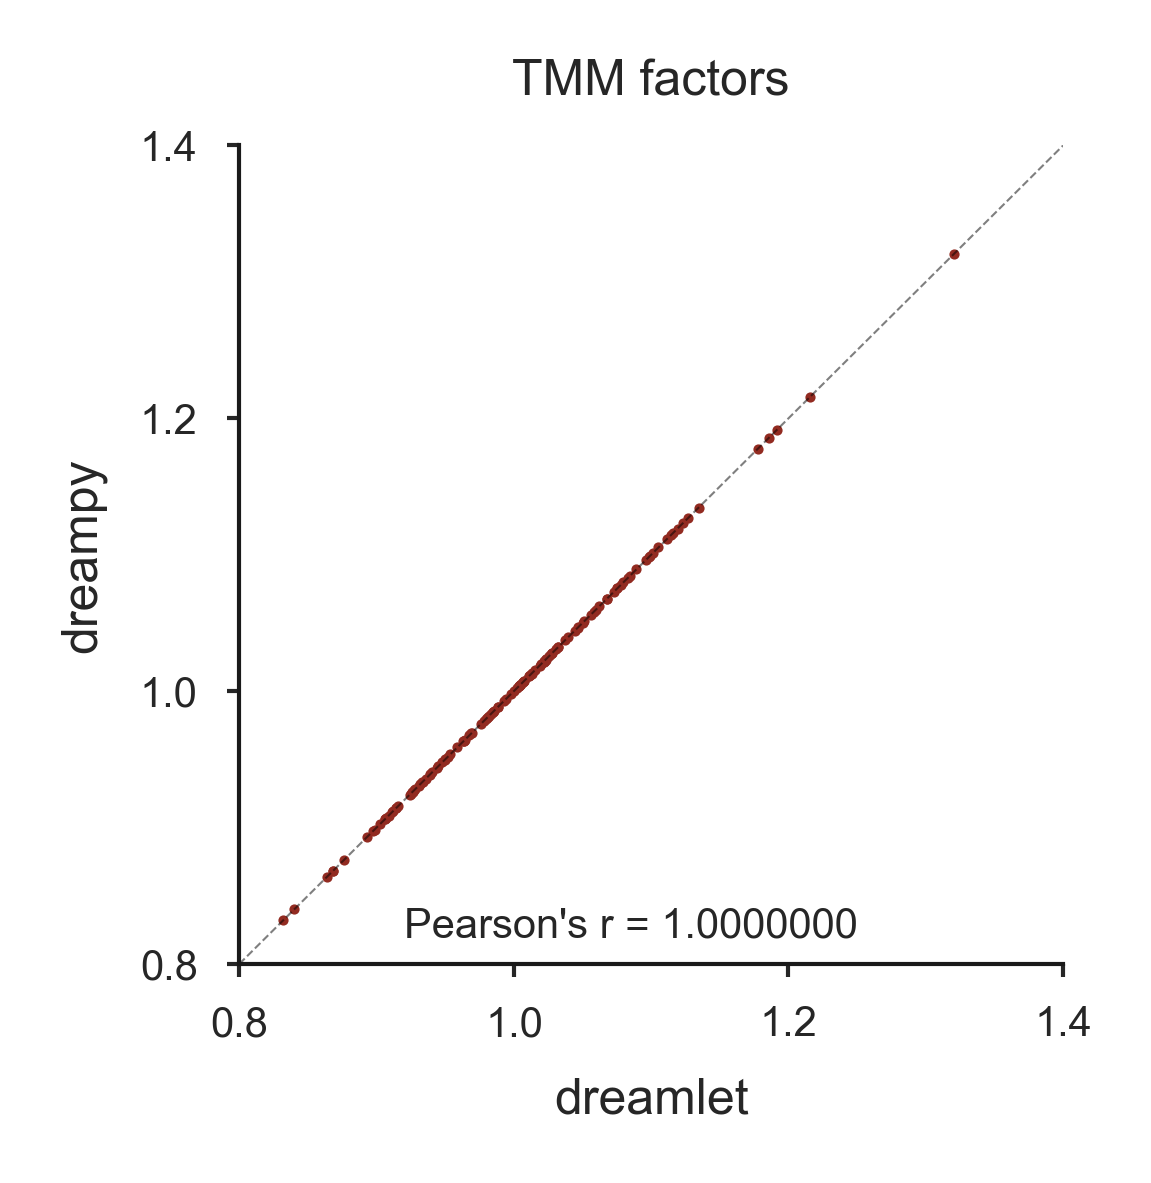

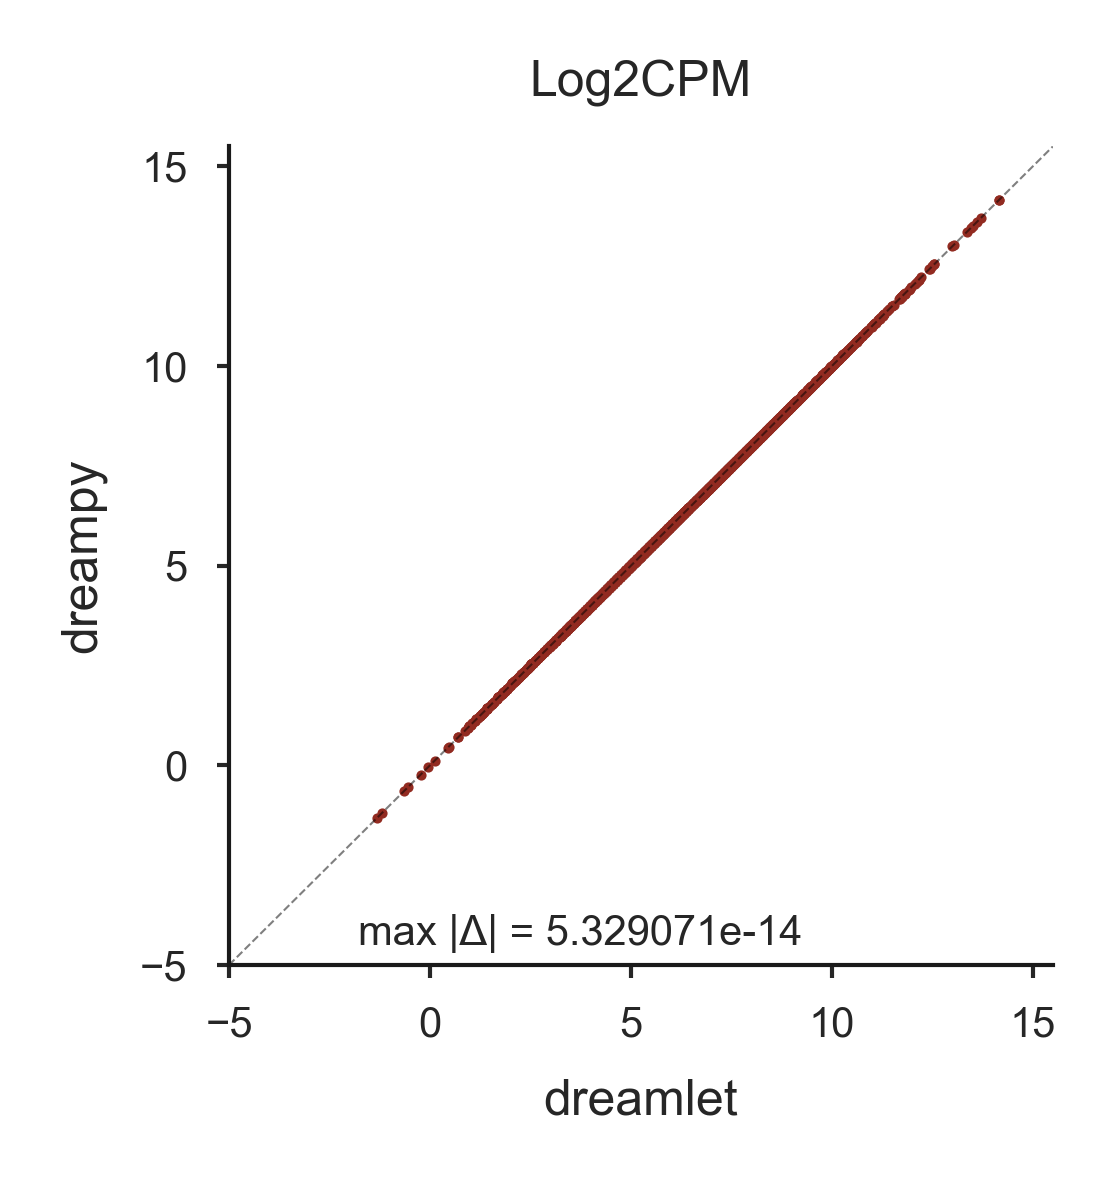

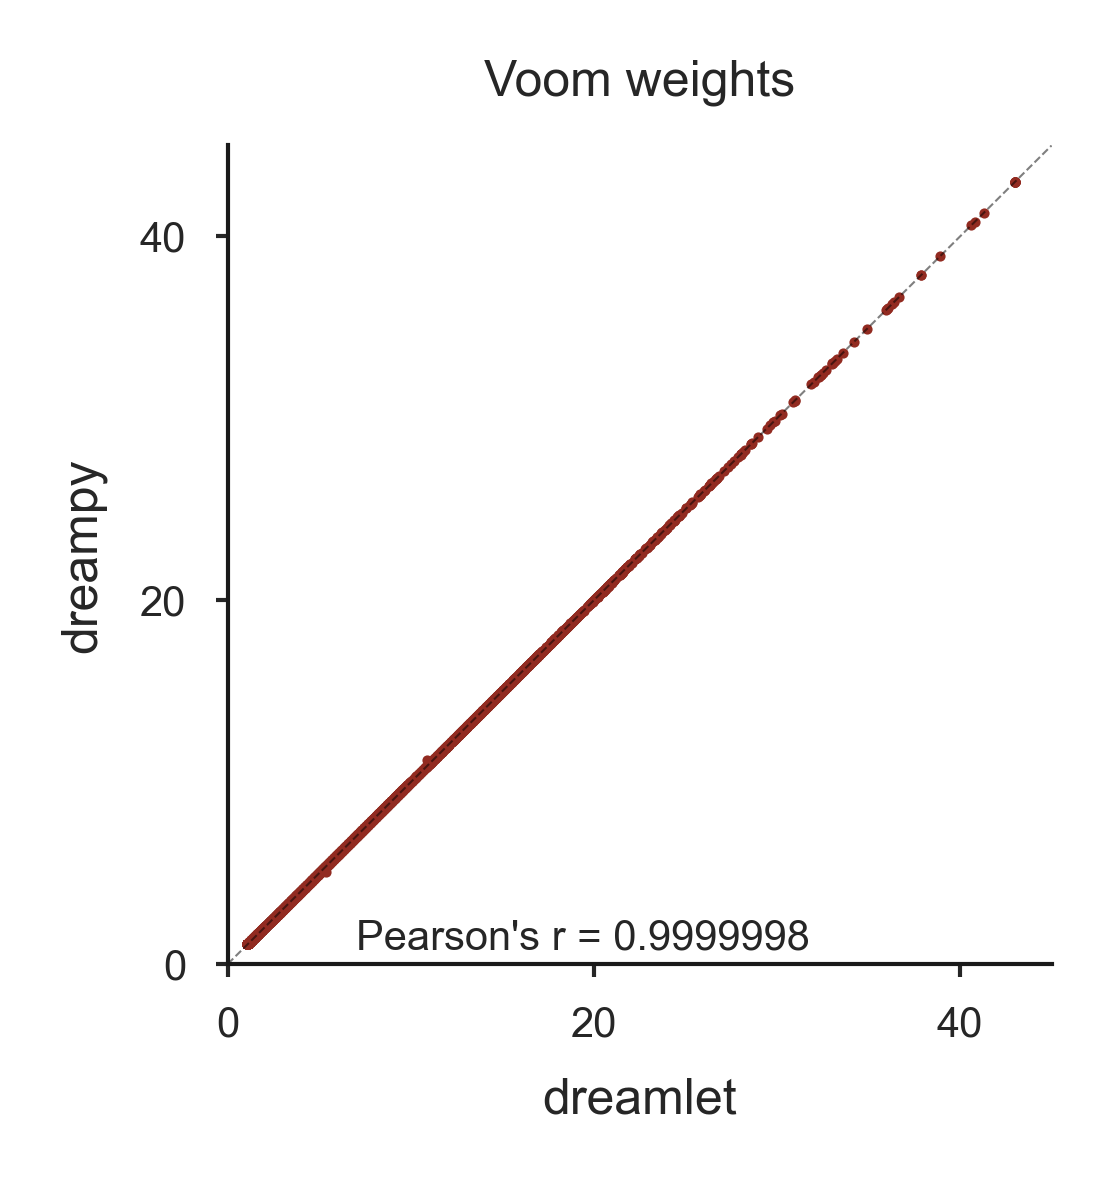

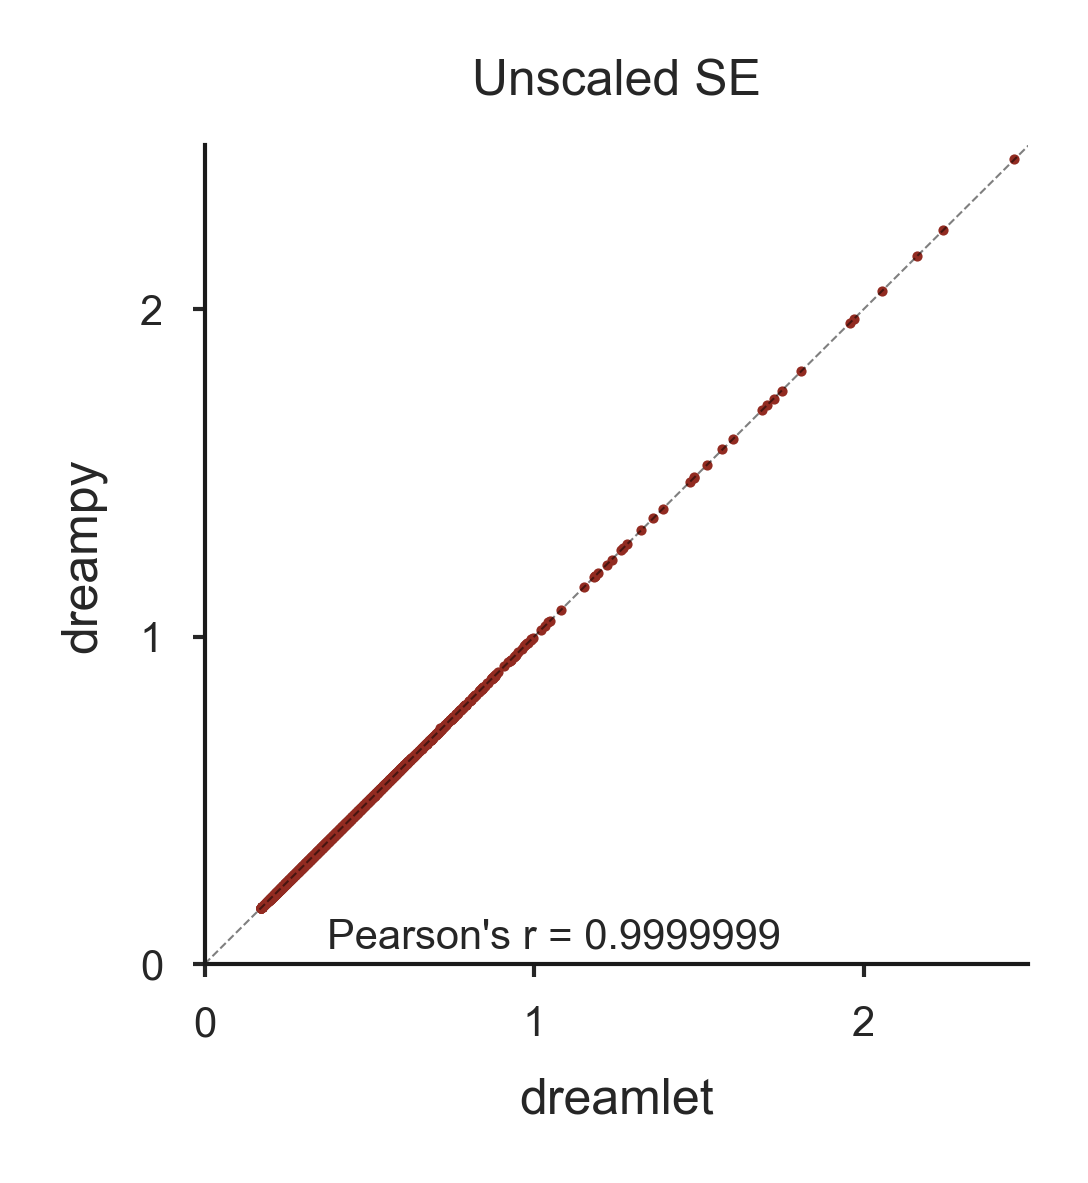

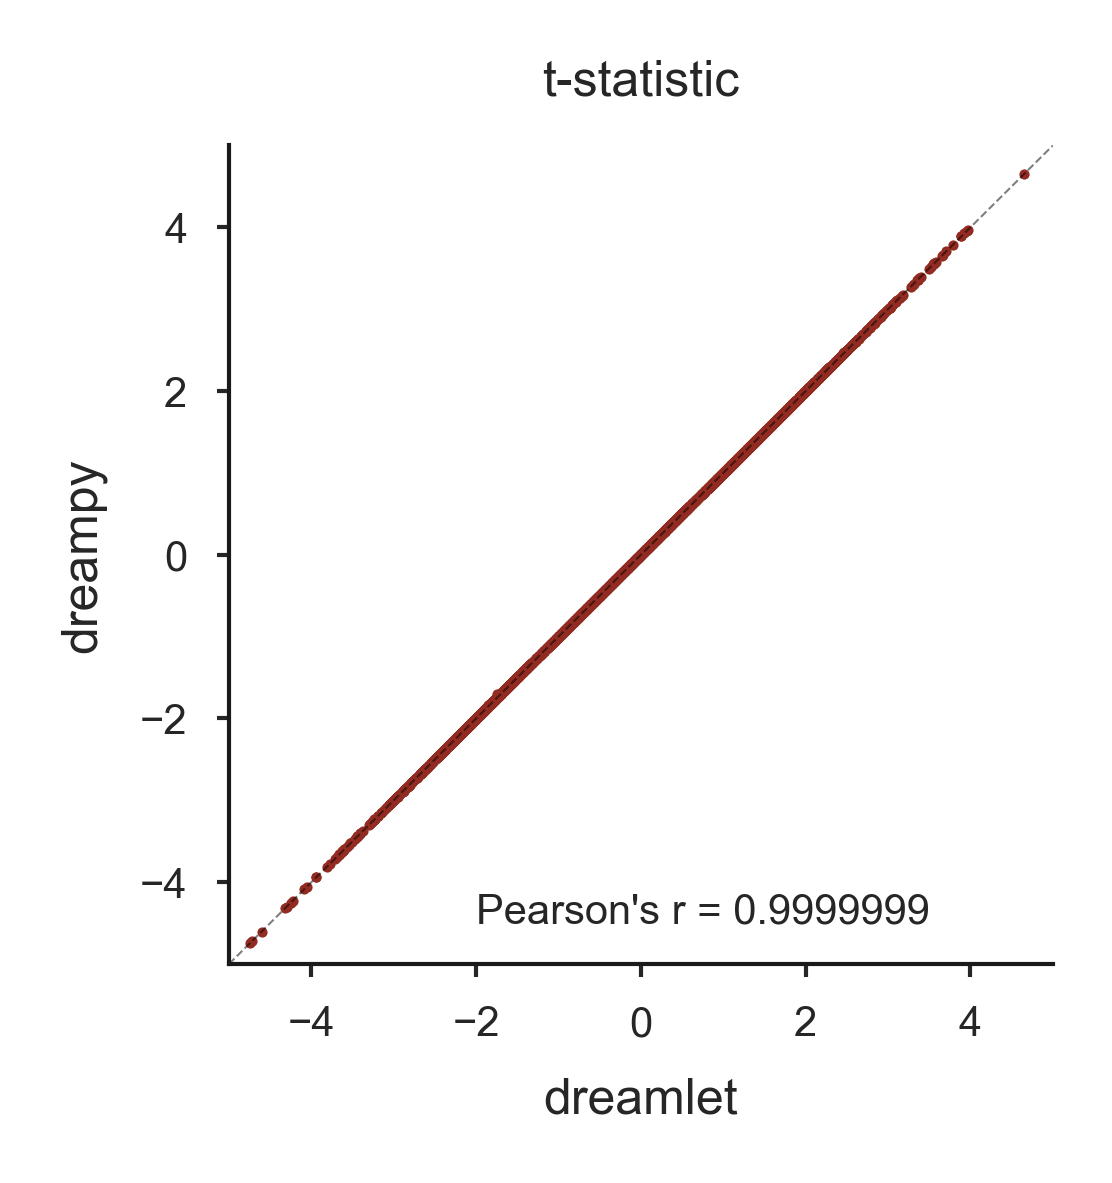

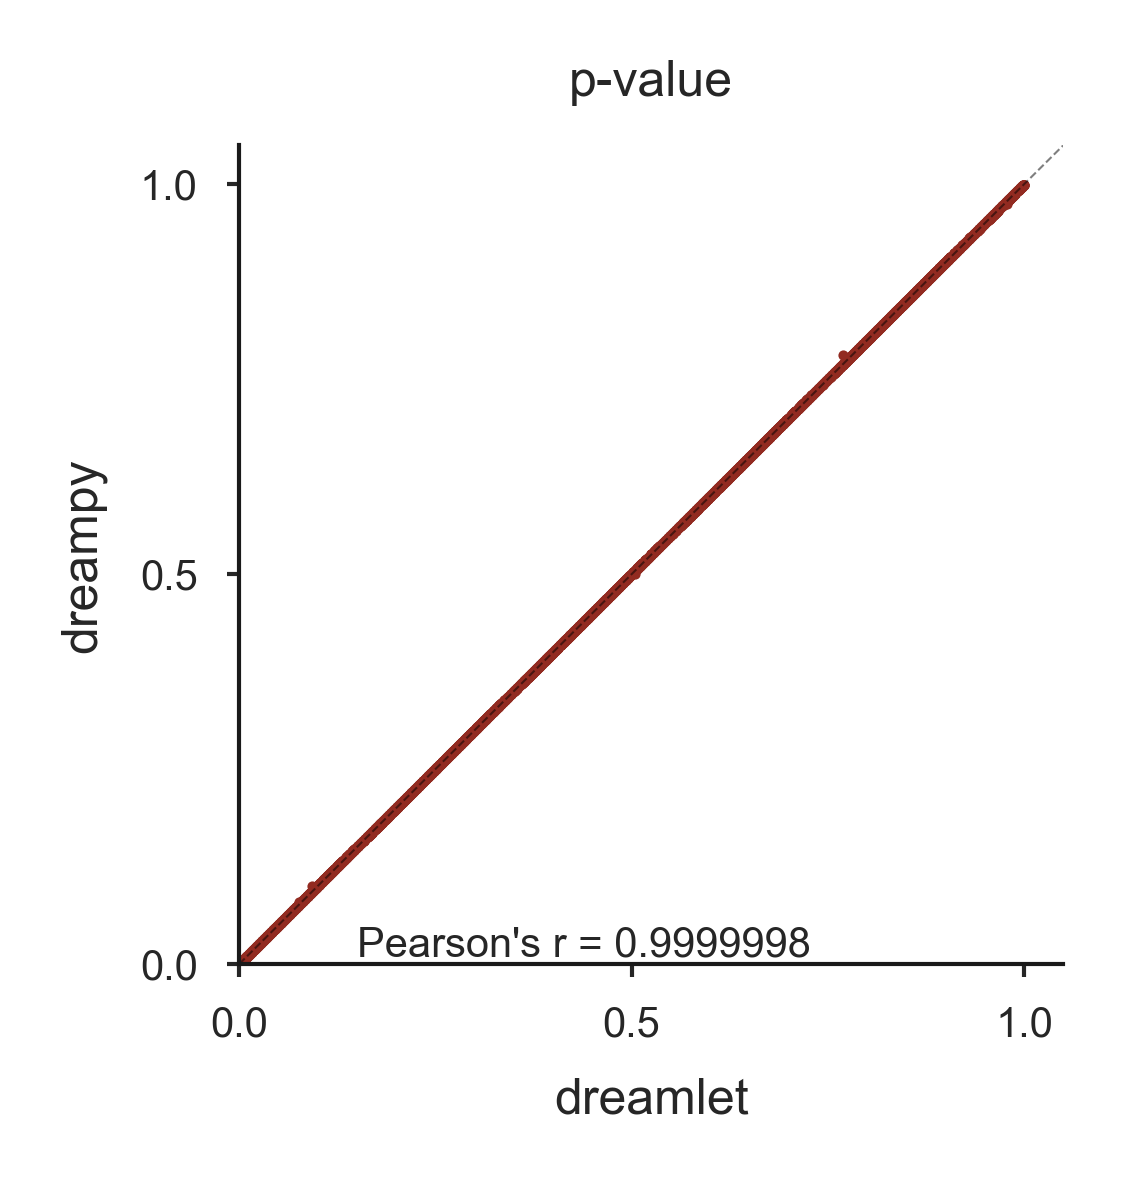

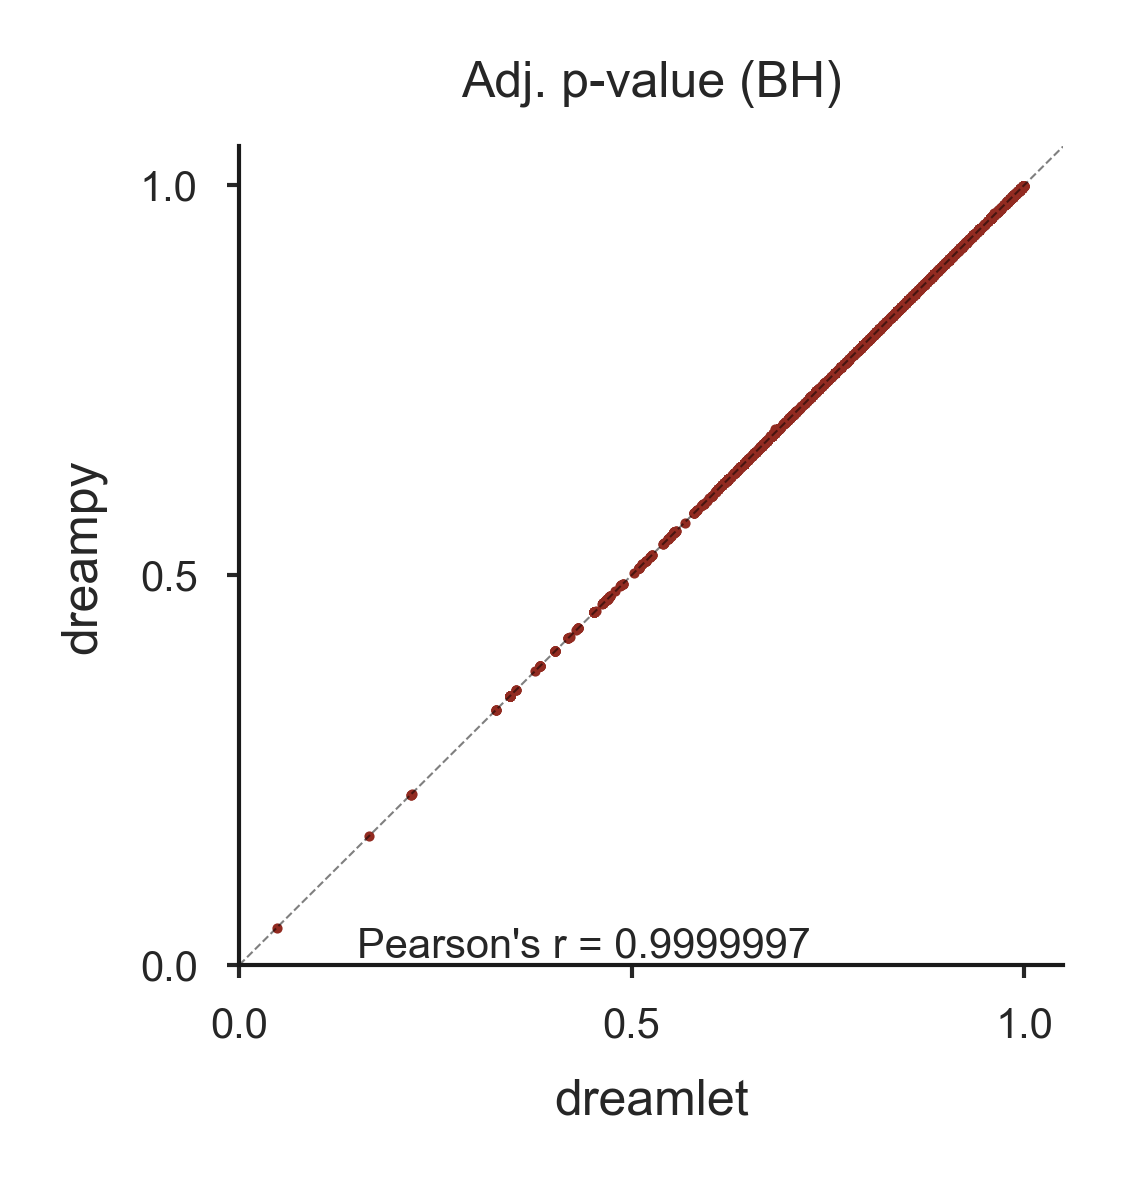

In [5]:
for spec in PLOTS:
    if spec["merge"] == "cols":
        data, x, y = load_merge_cols(assay_name, spec["comparison"],
                                     spec["col"], spec["col"])
    else:
        data = load_merge_ravel(assay_name, spec["comparison"])
        x, y = "r", "py"

    # Annotation on full data
    ann = spec["annotate_fn"](data[x], data[y])

    # Subsample for plotting only
    n_sample = spec.get("n_sample")
    if n_sample is not None and len(data) > n_sample:
        data = data.sample(n_sample, random_state=RANDOM_STATE)
    
    save_name = spec.get("save_name", spec["comparison"])

    data = data.sort_values(x)
    
    pl.scatter(data=data, x=x, y=y,
            xlabel="dreamlet", ylabel="dreampy",
            title=spec["title"], s=1.5, c="#922B21",
            lim=spec["lim"], tick_labels=spec["ticks"],
            annotate=ann, annotate_pos=spec["annotate_pos"],
            save=f"{FIGURES_PATH}/{save_name}.pdf")

### speed test

In [6]:
if (DATA_PATH / "timing.csv").exists():
    print("timing.csv found.")
    data = pd.read_csv(f"{DATA_PATH}/timing.csv", index_col=0)
    print("Data loaded.")
else:
    print("Creating timing.csv from time test .txts")
    filepaths = glob.glob(f"{DATA_PATH}/**/*timing*")
    timing = []
    for filepath in filepaths:
        timing_dict = {}
        filename = filepath.split("/")[-1]
        timing_dict['package'] = filename.split("_")[0]
        timing_dict['dataset'] = filename.split("_")[1]
        with open(filepath, encoding="utf-8") as file:
            timing_data = file.readlines()

        timing_dict['preprocess'] = timing_data[0].split(" ")[1]
        timing_dict['model_fit'] = timing_data[1].split(" ")[1]
        timing_dict['total'] = timing_data[2].split(" ")[1]

        timing.append(timing_dict)
    data = pd.DataFrame(timing)
    data['package'] = data['package'].replace({"R":"dreamlet", "py":"dreampy"})
    filename = f"{DATA_PATH}/timing.csv"
    print(f"Saving data to: {filename}")
    data.to_csv(filename)

timing.csv found.
Data loaded.


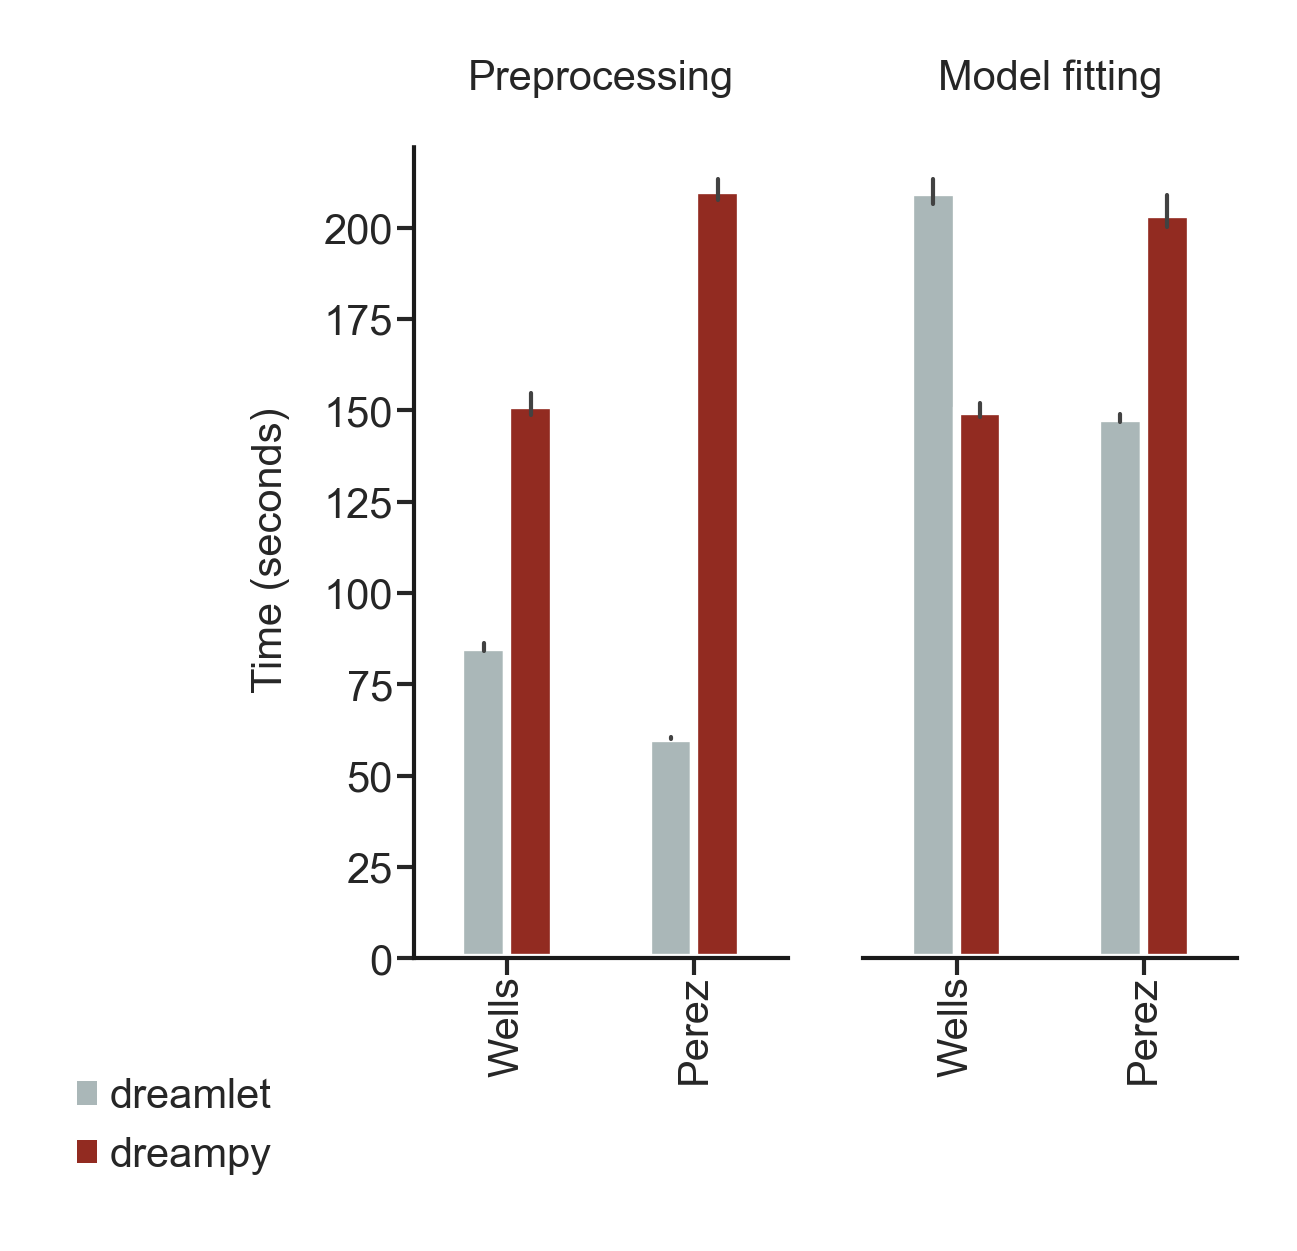

In [7]:
fig, axs = plt.subplots(1,2, sharey=False, figsize=(45*MM, 45*MM))
box_kwargs = dict(xticklabels=['Wells', 'Perez'], hue_order=['dreamlet', 'dreampy'], palette=["#AAB7B8", "#922B21"])
pl.timebar(data=data, x='dataset', y="preprocess", hue='package', ylabel="Time (seconds)", xlabel="",  title = "Preprocessing", legend=False, ax=axs[0], **box_kwargs)
pl.timebar(data=data, x='dataset', y="model_fit", hue='package', ylabel="", xlabel="", title = "Model fitting", ax=axs[1], **box_kwargs)

axs[1].spines[['left']].set_visible(False)
axs[1].tick_params(top=False, bottom=True, left=False, right=False, labelleft=False, labelbottom=True)

save = f"{FIGURES_PATH}/speed_test.pdf"
plt.savefig(save, dpi=400, bbox_inches="tight")
plt.show()

## <b style='color:magenta'> Figure 3


### DE Numbers

In [8]:
# Remove proliferating as indeterminate cell type—mixture of various 
# lineages-and PB as PB is perfect collinear between that condition 
# indicator and that batch indicator

# ── Helpers ──────────────────────────────────────────────────────────
def load_results(key):
    exclude = {"Prolif", "PB"}
    filepaths = [
        fp for fp in glob.glob(f"{DATA_PATH}/perez2022/{key}")
        if not any(ex in fp for ex in exclude)
    ]

    dfs = []
    for filepath in filepaths:
        df = pd.read_csv(filepath, index_col=0)
        dfs.append(df)
    data = pd.concat(dfs)

    data['assay_fig'] = data['assay'].replace(DICTIONARIES["assay_fig_names"])

    return data

def value_counts(data):
    mask = (data["adj_p_val"] < 0.05)
    vc = data[mask]['assay_fig'].value_counts()
    vc = pd.DataFrame(vc)
    vc.columns = ['sig']
    mask = (data["adj_p_val"] < 0.05) & (np.abs(data["logfc"]) > 0.5 )
    vc['logfc'] = data[mask]['assay_fig'].value_counts()
    
    return vc.reset_index() 

In [9]:
if (DATA_PATH / "no_sig_genes.csv").exists():
    print("no_sig_genes.csv found.")
    vc = pd.read_csv(f"{DATA_PATH}/no_sig_genes.csv", index_col=0)
    print("Data loaded.")
else:
    data_full = load_results("*py_results.csv")
    vc_full = value_counts(data_full)
    vc_full['cohort'] = 'Full cohort'

    data_sens = load_results("*sensitivity_results.csv")
    vc_sens = value_counts(data_sens)
    vc_sens['cohort'] = '-ImmVar'

    vc = pd.concat([vc_full, vc_sens], axis=0)

    vc.to_csv(f"{DATA_PATH}/no_sig_genes.csv")

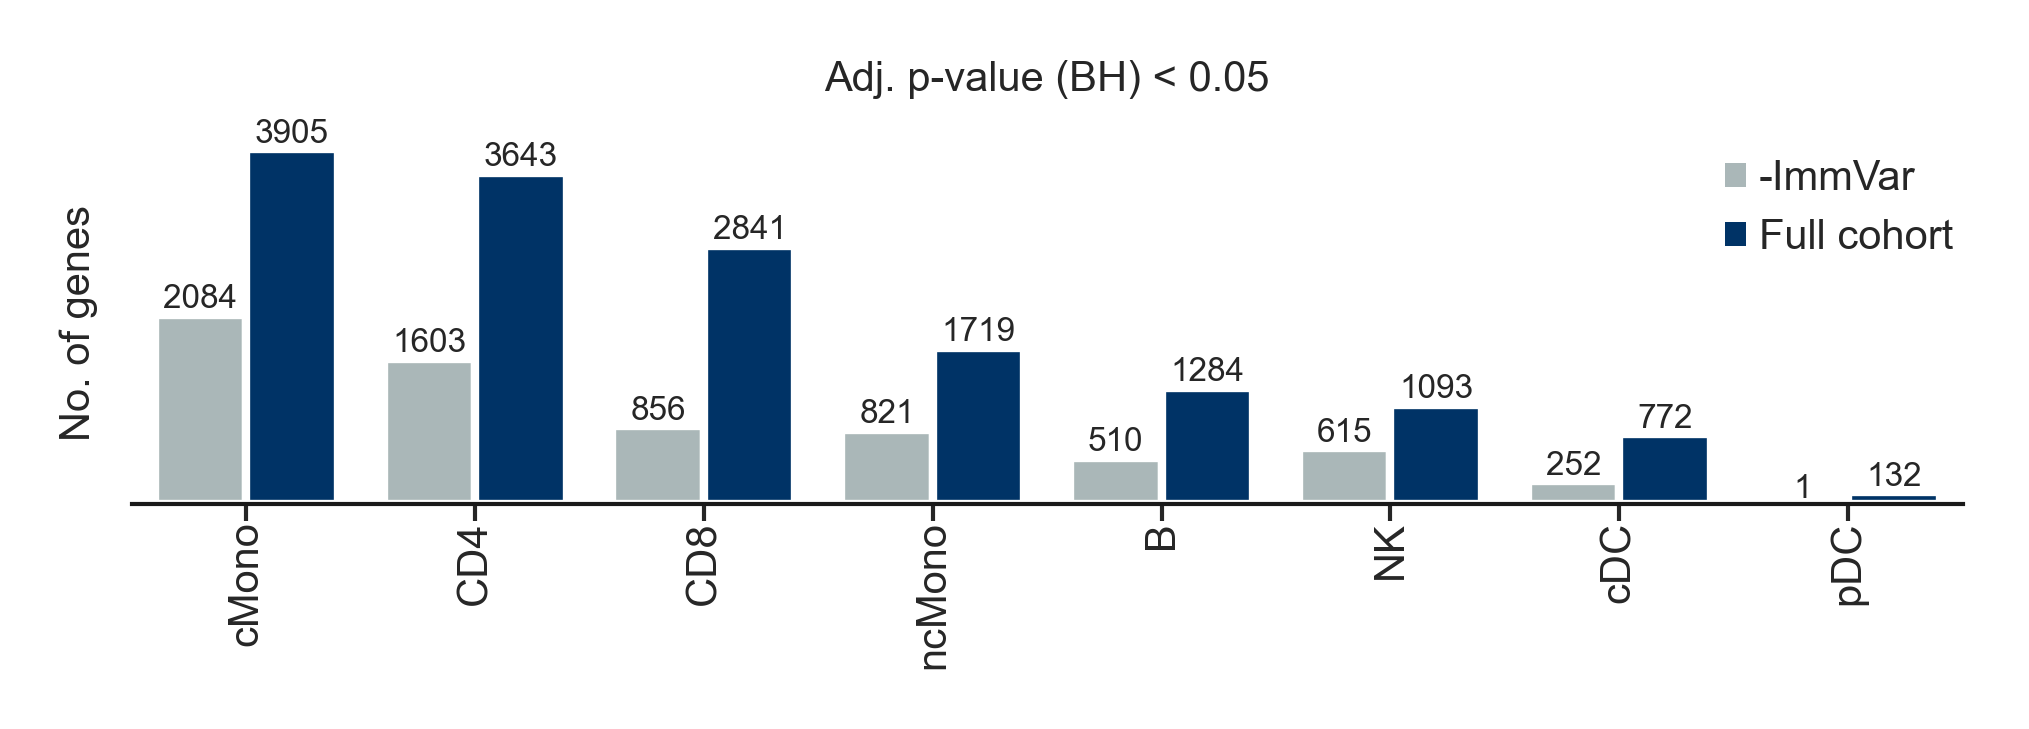

In [10]:
kwargs = dict(hue_order=["-ImmVar", "Full cohort"], palette=["#AAB7B8","#003366"])
pl.numberbar(data=vc, x='assay_fig', y = 'sig', hue='cohort', xlabel='', ylabel="No. of genes", ylim=(0, 4000), title= "Adj. p-value (BH) < 0.05", figsize = (100*MM, 20*MM), **kwargs)
save = f"{FIGURES_PATH}/no_sig_genes.pdf"
plt.savefig(save, dpi=400, bbox_inches="tight")
plt.show()

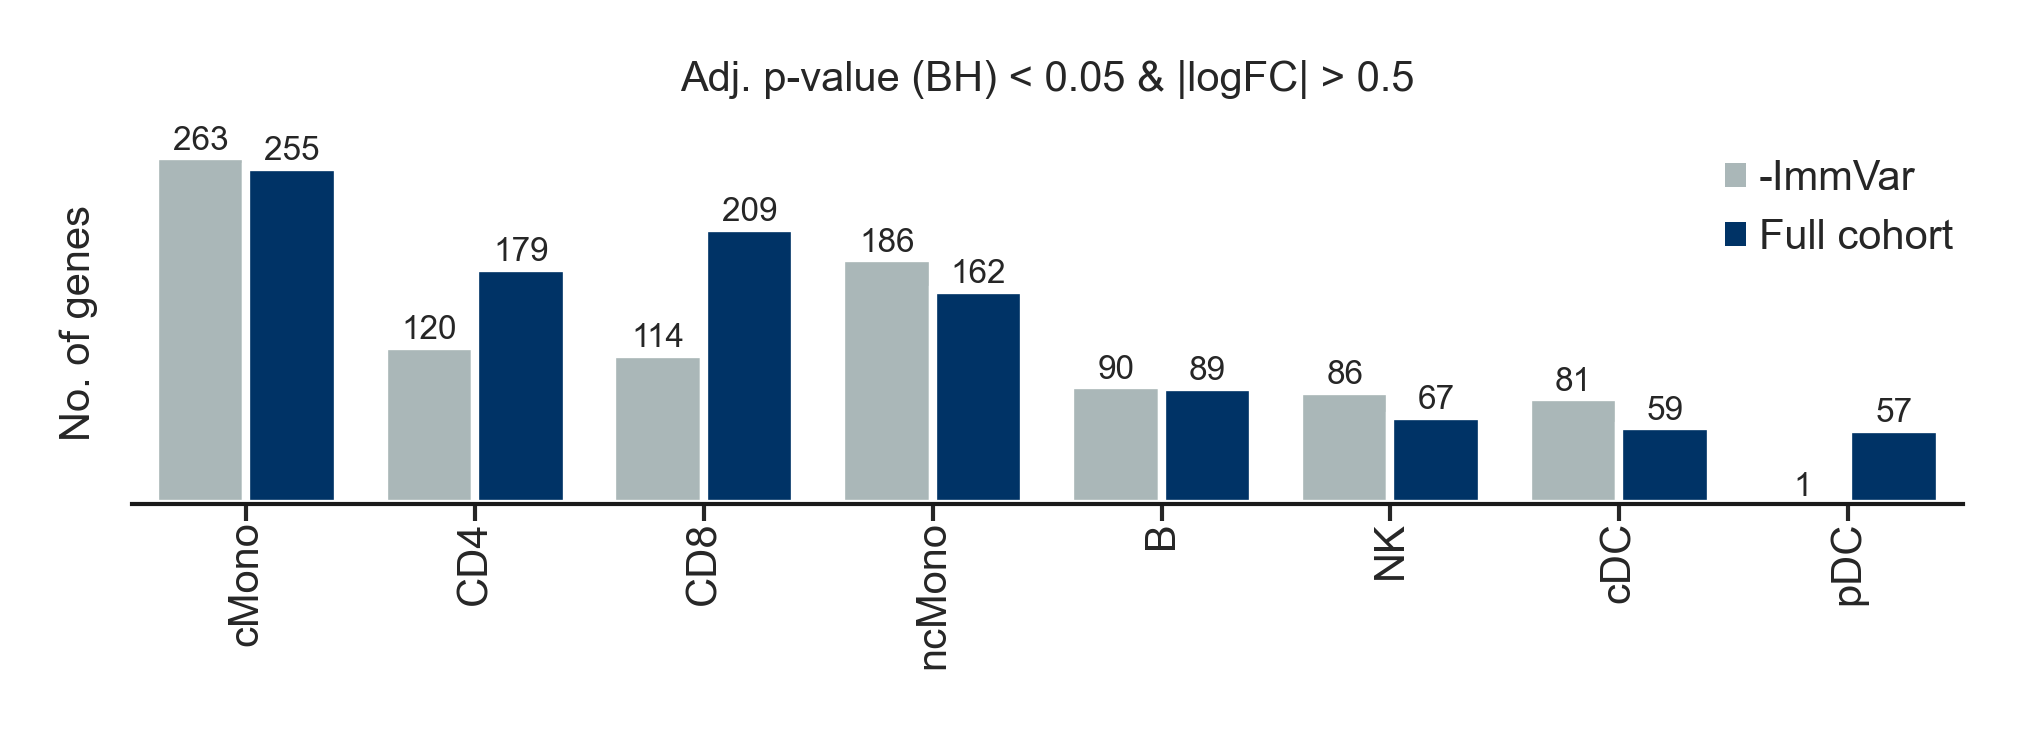

In [11]:
pl.numberbar(data=vc, x='assay_fig', y = 'logfc', hue='cohort', xlabel='', ylabel="No. of genes", title= "Adj. p-value (BH) < 0.05 & |logFC| > 0.5",ylim=(0, 275), figsize = (100*MM, 20*MM), **kwargs)
save = f"{FIGURES_PATH}/no_sig_logfc_genes.pdf"
plt.savefig(save, dpi=400, bbox_inches="tight")
plt.show()

### venn

In [12]:
# ── Helper ──────────────────────────────────────────────────────────
def thresold_genes(data):
    return data[(data["adj_p_val"] < 0.05)]['id'].unique().tolist()

if (DATA_PATH / "venn.csv").exists():
    print("venn.csv found.")
    venn_genes = pd.read_csv(f"{DATA_PATH}/venn.csv", index_col=0)
    genes_full = venn_genes[venn_genes['full']].index
    genes_sens = venn_genes[venn_genes['sens']].index
    print("Data loaded.")
else:
    genes_full = thresold_genes(data_full)
    genes_sens = thresold_genes(data_sens)
    
    venn_genes = pd.DataFrame(index=list(set(genes_full) | set(genes_sens)))
    venn_genes['full'] = venn_genes.index.isin(genes_full)
    venn_genes['sens'] = venn_genes.index.isin(genes_sens)
    venn_genes.to_csv(f"{DATA_PATH}/venn.csv")

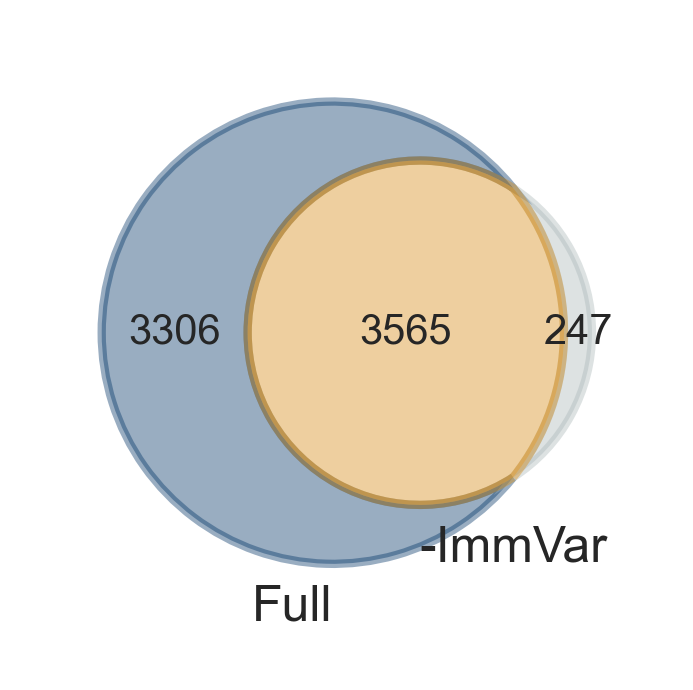

In [13]:
fig, ax = plt.subplots(1, 1, figsize=[60*MM, 30*MM])
v = venn2([set(genes_full), set(genes_sens)], set_labels=('Full', '-ImmVar'), ax=ax)
v.get_patch_by_id('10').set_color("#003366")
v.get_patch_by_id('01').set_color("#AAB7B8")
v.get_patch_by_id('11').set_color("#D68910")
save = f"{FIGURES_PATH}/venn.pdf"
plt.savefig(save, dpi=400, bbox_inches="tight")
plt.show()

### gene signature

In [14]:
if (DATA_PATH / "heatmap_sig_genes.csv").exists():
    print("heatmap_sig_genes.csv found.")
    data = pd.read_csv(f"{DATA_PATH}/heatmap_sig_genes.csv", index_col=0)
    print("Data loaded.")
else:
    mask  = (data_full["adj_p_val"] < 0.05) & (np.abs(data_full["logfc"]) > 0.5)
    vc = data_full[mask]['id'].value_counts()
    mask = (vc >= 5)
    genes = vc[mask].index.tolist()
    data = data_full[data_full["id"].isin(genes)].copy()
    data.to_csv(f"{DATA_PATH}/heatmap_sig_genes.csv")

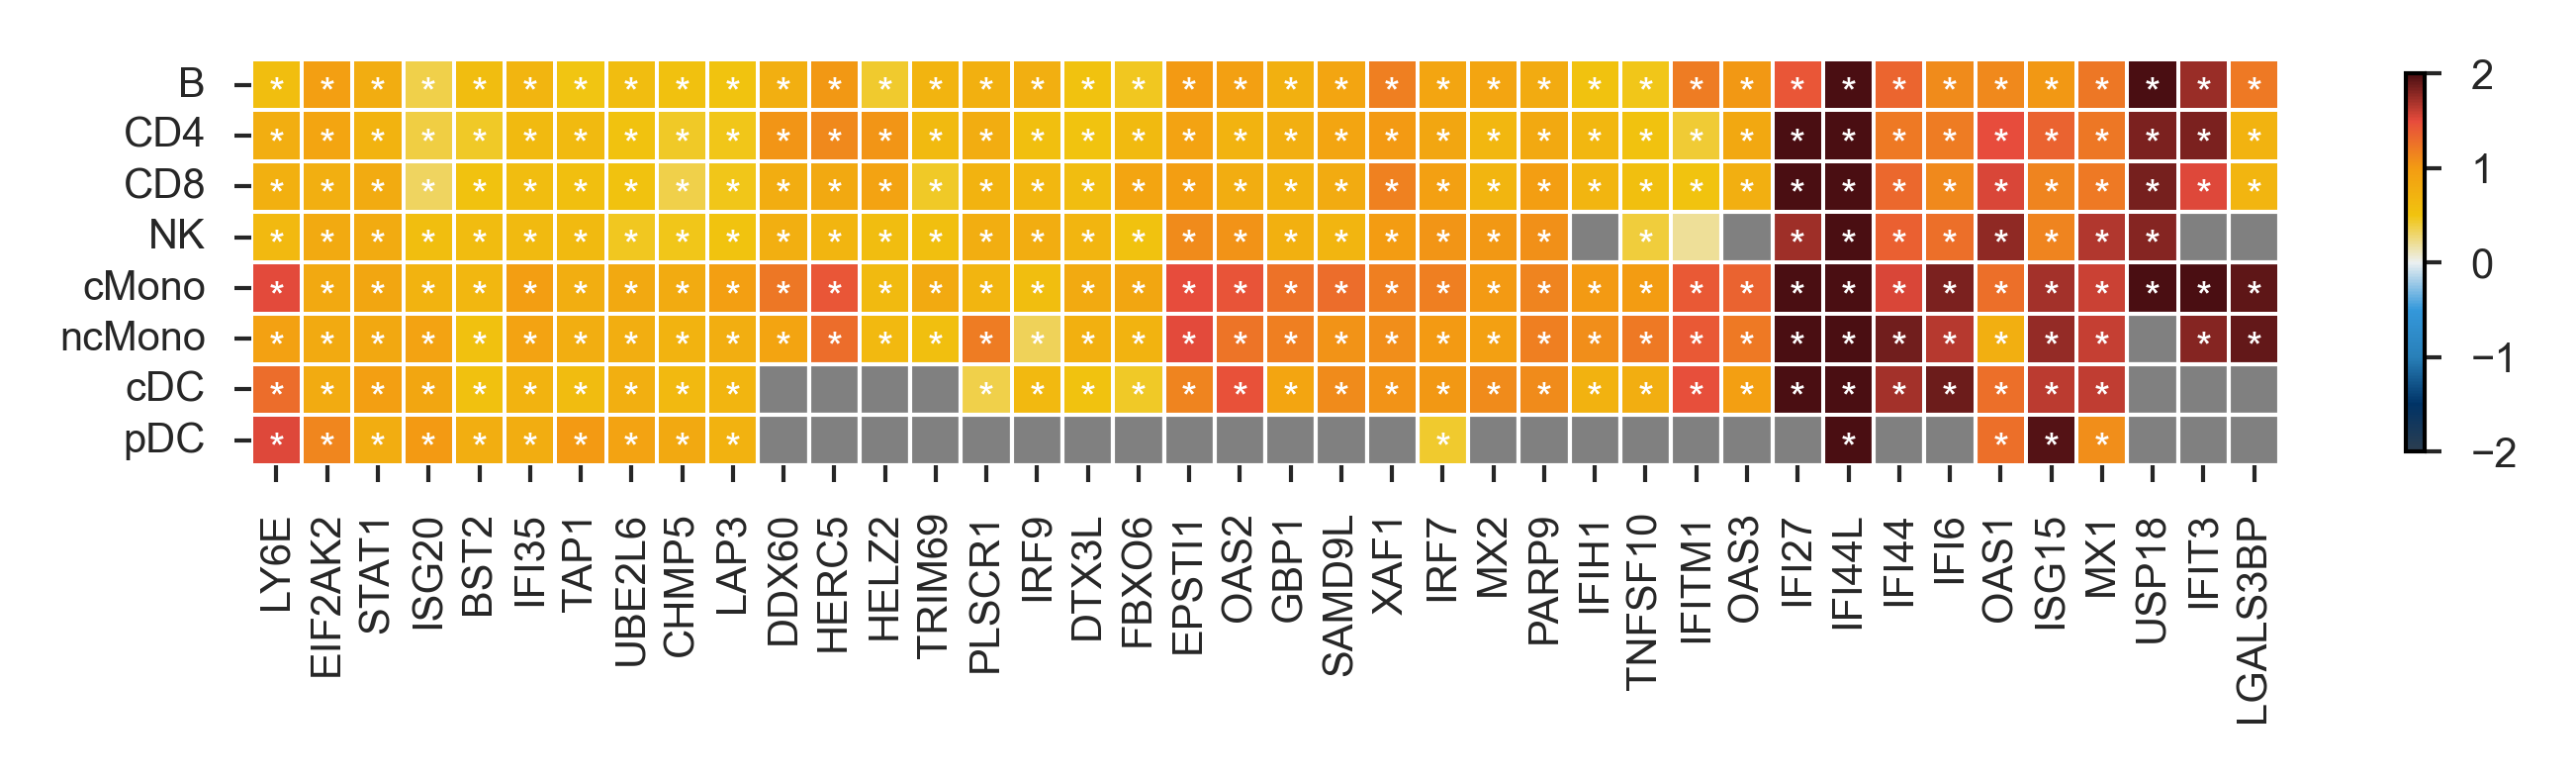

In [15]:
order = ['B', 'CD4', 'CD8', 'NK', 'cMono', 'ncMono', 'cDC', 'pDC']
data_logfc = data.pivot_table(index="id", columns="assay_fig", values="logfc")
Z = linkage(data_logfc.fillna(0).values, method='ward', metric='euclidean')
order_cluster = leaves_list(Z)

data_logfc = data_logfc.iloc[order_cluster,:]
data_logfc = data_logfc.loc[:,order].T

data_sig = data.pivot_table(index="id", columns="assay_fig", values="adj_p_val")
data_sig = data_sig.iloc[order_cluster,:]
data_sig = data_sig.loc[:,order].T

save = f"{FIGURES_PATH}/heatmap.pdf"
pl.heatmap(data=data_logfc, significant=data_sig, figsize = (MM*140,MM*140), save=save)